# Mojo 1.2 Interactive 3D Graphics Showcase

Four self-contained **pure Mojo 1.2** 3D rendering & simulation engines — zero external Python plotting libraries required:

1. **Core 3D Math, `SIMD` Vector Kernel & Pure-Mojo Truecolor PNG Encoder** (`Vec3`, `SIMD[DType.float64, 4]`, RFC 1950/1951 PNG)
2. **Whitted 3D Raytracer** — multi-bounce mirror reflections, Blinn-Phong highlights, shadows & perspective checkerboard
3. **3D Signed Distance Field (SDF) Raymarcher** — twisted torus smoothly fused (`smin`) with orbiting metaspheres & ambient occlusion
4. **3D Lorenz Strange Attractor** — 80,000 chaotic 3D phase-space steps with perspective volumetric plasma glow
5. **Z-Buffered 3D Parametric Wave Surface** — dual-source ripple interference mesh with depth occlusion & wireframe isolines

> **TurboMojo Shortcuts:** Press **`Ctrl-Enter`** (or **`Shift-Enter`**) to run a cell, **`Compile > Run queue: all cells`** to run all, and **`Text > Open cell plot preview`** to inspect the high-resolution 24-bit PNG renders in the terminal!

In [1]:
from std.collections import List
from std.math import sqrt, sin, cos, exp
from std.pathlib import Path
from std.time import perf_counter_ns


@fieldwise_init
struct Vec3(Copyable, Movable, ImplicitlyCopyable, Writable):
    var x: Float64
    var y: Float64
    var z: Float64

    def __add__(self, o: Self) -> Self:
        return Self(self.x + o.x, self.y + o.y, self.z + o.z)

    def __sub__(self, o: Self) -> Self:
        return Self(self.x - o.x, self.y - o.y, self.z - o.z)

    def __neg__(self) -> Self:
        return Self(-self.x, -self.y, -self.z)

    def __mul__(self, s: Float64) -> Self:
        return Self(self.x * s, self.y * s, self.z * s)

    def hadamard(self, o: Self) -> Self:
        return Self(self.x * o.x, self.y * o.y, self.z * o.z)

    def dot(self, o: Self) -> Float64:
        return self.x * o.x + self.y * o.y + self.z * o.z

    def cross(self, o: Self) -> Self:
        return Self(
            self.y * o.z - self.z * o.y,
            self.z * o.x - self.x * o.z,
            self.x * o.y - self.y * o.x,
        )

    def length(self) -> Float64:
        return sqrt(self.dot(self))

    def normalized(self) -> Self:
        var len_v = self.length()
        if len_v <= 1e-12:
            return Self(0.0, 0.0, 0.0)
        var inv = 1.0 / len_v
        return Self(self.x * inv, self.y * inv, self.z * inv)

    def reflect(self, n: Self) -> Self:
        return self - n * (2.0 * self.dot(n))

    def lerp(self, b: Self, t: Float64) -> Self:
        return self * (1.0 - t) + b * t

    def rot_y(self, a: Float64) -> Self:
        var ca = cos(a)
        var sa = sin(a)
        return Self(self.x * ca + self.z * sa, self.y, -self.x * sa + self.z * ca)

    def rot_x(self, a: Float64) -> Self:
        var ca = cos(a)
        var sa = sin(a)
        return Self(self.x, self.y * ca - self.z * sa, self.y * sa + self.z * ca)

    def write_to(self, mut writer: Some[Writer]):
        writer.write("Vec3(", self.x, ", ", self.y, ", ", self.z, ")")


def clamp01(v: Float64) -> Float64:
    if v < 0.0:
        return 0.0
    if v > 1.0:
        return 1.0
    return v


def tone_u8(v: Float64) -> UInt8:
    var mapped = v / (1.0 + 0.35 * v)
    var gamma = sqrt(clamp01(mapped))
    return UInt8(Int(gamma * 255.0 + 0.5))


def _append_be32(mut out: List[UInt8], val: UInt32):
    out.append(UInt8((val >> 24) & 255))
    out.append(UInt8((val >> 16) & 255))
    out.append(UInt8((val >> 8) & 255))
    out.append(UInt8(val & 255))


def _crc32_chunk(tag: String, payload: List[UInt8]) -> UInt32:
    var crc: UInt32 = 0xFFFFFFFF
    for b in tag.as_bytes():
        crc ^= UInt32(b)
        for _ in range(8):
            if (crc & 1) != 0:
                crc = (crc >> 1) ^ 0xEDB88320
            else:
                crc >>= 1
    for i in range(len(payload)):
        crc ^= UInt32(payload[i])
        for _ in range(8):
            if (crc & 1) != 0:
                crc = (crc >> 1) ^ 0xEDB88320
            else:
                crc >>= 1
    return crc ^ 0xFFFFFFFF


def _write_png_chunk(mut out: List[UInt8], tag: String, payload: List[UInt8]):
    _append_be32(out, UInt32(len(payload)))
    for b in tag.as_bytes():
        out.append(b)
    for i in range(len(payload)):
        out.append(payload[i])
    _append_be32(out, _crc32_chunk(tag, payload))


def save_rgb_png(path: String, w: Int, h: Int, rgb: List[UInt8]) raises:
    """Write a valid 24-bit truecolor PNG (RFC 1950/1951) using pure Mojo."""
    var raw = List[UInt8](capacity=(w * 3 + 1) * h)
    for y in range(h):
        raw.append(0)  # Filter 0 (None)
        var row_off = y * w * 3
        for x in range(w * 3):
            raw.append(rgb[row_off + x])

    var idat = List[UInt8](capacity=len(raw) + 64)
    idat.append(0x78)
    idat.append(0x01)
    var pos = 0
    var total = len(raw)
    var s1: UInt32 = 1
    var s2: UInt32 = 0
    while pos < total:
        var chunk_n = min(65535, total - pos)
        var is_last: UInt8 = 1 if (pos + chunk_n >= total) else 0
        idat.append(is_last)
        var ln16 = UInt16(chunk_n)
        var nln16 = ~ln16
        idat.append(UInt8(ln16 & 255))
        idat.append(UInt8((ln16 >> 8) & 255))
        idat.append(UInt8(nln16 & 255))
        idat.append(UInt8((nln16 >> 8) & 255))
        for k in range(chunk_n):
            var byte_v = raw[pos + k]
            idat.append(byte_v)
            s1 = (s1 + UInt32(byte_v)) % 65521
            s2 = (s2 + s1) % 65521
        pos += chunk_n
    _append_be32(idat, (s2 << 16) | s1)

    var png = List[UInt8](capacity=len(idat) + 64)
    for sig_b in [UInt8(0x89), 0x50, 0x4E, 0x47, 0x0D, 0x0A, 0x1A, 0x0A]:
        png.append(sig_b)

    var ihdr = List[UInt8](capacity=13)
    _append_be32(ihdr, UInt32(w))
    _append_be32(ihdr, UInt32(h))
    ihdr.append(8)  # 8-bit depth
    ihdr.append(2)  # RGB truecolor
    ihdr.append(0)
    ihdr.append(0)
    ihdr.append(0)
    _write_png_chunk(png, "IHDR", ihdr)
    _write_png_chunk(png, "IDAT", idat)
    _write_png_chunk(png, "IEND", List[UInt8]())
    Path(path).write_bytes(png[:])


def render_ascii_strip(rgb: List[UInt8], w: Int, h: Int, cols: Int = 52, rows: Int = 4) -> String:
    """Compact multi-level Unicode luminance strip for inline notebook cell preview."""
    var ramp = List[String]()
    ramp.append(" ")
    ramp.append("·")
    ramp.append("░")
    ramp.append("▒")
    ramp.append("▓")
    ramp.append("█")
    var lines = List[String]()
    for r in range(rows):
        var py = (r * h) // rows + h // (rows * 2)
        var row_s = String("  │")
        for c in range(cols):
            var px = (c * w) // cols + w // (cols * 2)
            var idx = (py * w + px) * 3
            var lum = (
                0.299 * Float64(rgb[idx])
                + 0.587 * Float64(rgb[idx + 1])
                + 0.114 * Float64(rgb[idx + 2])
            ) / 255.0
            var bi = min(5, max(0, Int(lum * 5.99)))
            row_s += ramp[bi]
        row_s += "│"
        lines.append(row_s)
    return "\n".join(lines)


def bench_simd_core():
    var simd_t0 = perf_counter_ns()
    var acc_simd = SIMD[DType.float64, 4](0.0)
    var vx = SIMD[DType.float64, 4](1.0, 2.0, 3.0, 4.0)
    var vy = SIMD[DType.float64, 4](0.5, 1.5, 2.5, 3.5)
    for i in range(250_000):
        var s = Float64(i) * 1e-6
        acc_simd += (vx + s) * (vy - s)
    var simd_ms = Float64(Int(perf_counter_ns() - simd_t0)) / 1e6
    print(
        "3D Engine Ready | 1M SIMD f64 lanes in",
        Float64(Int(simd_ms * 100.0)) / 100.0,
        "ms | checksum =",
        Int(acc_simd.reduce_add()),
    )


bench_simd_core()

3D Engine Ready | 1M SIMD f64 lanes in 0.42 ms | checksum = 6166667


## Scene 1: Whitted 3D Raytracer (Reflections, Specular Highlights & Shadows)

Traces primary, shadow, and **3-bounce recursive mirror reflection** rays against four glossy metallic spheres over an infinite perspective checkerboard plane with atmospheric horizon scattering.

Scene 1 [Whitted Raytracer] 420x240 (4x SSAA) rendered in 34 ms
  │░░░░░░░░░░░░░░░░░░░░░░░░░░░░▒▒▒▓▒░░░░░░░░░░░░░░░░░░░│
  │░░░▒▒▒▒▒▒▓▓▓▓▒▒░░░░▒░░░░░▒▒▒▒▒▒▒▒▒░░░░▒▒▒▒▒▓▓▓▓▒░░░░│
  │··░·░░░▒▒▒▒▒▒░····░░░░░░░░········░░░░░░░░░░▒▒▓▒▒░▒▒│


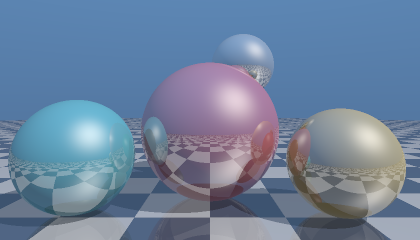

In [2]:
@fieldwise_init
struct Sphere3D(Copyable, Movable, ImplicitlyCopyable):
    var center: Vec3
    var radius: Float64
    var color: Vec3
    var reflectivity: Float64


def intersect_sphere(ro: Vec3, rd: Vec3, s: Sphere3D) -> Float64:
    var oc = ro - s.center
    var b = oc.dot(rd)
    var c = oc.dot(oc) - s.radius * s.radius
    var disc = b * b - c
    if disc < 0.0:
        return -1.0
    var sq = sqrt(disc)
    var t1 = -b - sq
    if t1 > 0.001:
        return t1
    var t2 = -b + sq
    return t2 if t2 > 0.001 else -1.0


def trace_ray_scene(ro_in: Vec3, rd_in: Vec3, spheres: List[Sphere3D]) -> Vec3:
    var ro = ro_in
    var rd = rd_in
    var throughput = Vec3(1.0, 1.0, 1.0)
    var accum = Vec3(0.0, 0.0, 0.0)
    var sun_dir = Vec3(0.58, 0.72, -0.38).normalized()

    for _ in range(3):
        var best_t = 1e9
        var hit_kind = 0  # 0 = sky, 1 = sphere, 2 = floor
        var hit_idx = -1

        for si in range(len(spheres)):
            var ts = intersect_sphere(ro, rd, spheres[si])
            if ts > 0.0 and ts < best_t:
                best_t = ts
                hit_kind = 1
                hit_idx = si

        if rd.y < -1e-4:
            var tf = (-1.0 - ro.y) / rd.y
            if tf > 0.001 and tf < best_t and tf < 34.0:
                best_t = tf
                hit_kind = 2

        if hit_kind == 0:
            var sky_t = clamp01(0.5 * (rd.y + 1.0))
            var sky = Vec3(0.05, 0.07, 0.14).lerp(Vec3(0.18, 0.42, 0.82), sky_t)
            var sun_glow = max(0.0, rd.dot(sun_dir))
            var sun_pow = sun_glow * sun_glow * sun_glow * sun_glow
            sky = sky + Vec3(1.0, 0.82, 0.55) * (0.45 * sun_pow * sun_pow)
            accum = accum + throughput.hadamard(sky)
            break

        var pos = ro + rd * best_t
        var norm: Vec3
        var base_col: Vec3
        var refl: Float64

        if hit_kind == 1:
            norm = (pos - spheres[hit_idx].center).normalized()
            base_col = spheres[hit_idx].color
            refl = spheres[hit_idx].reflectivity
        else:
            norm = Vec3(0.0, 1.0, 0.0)
            var gx = Int(pos.x + 100.0)
            var gz = Int(pos.z + 100.0)
            var checker = (gx + gz) & 1
            base_col = Vec3(0.86, 0.88, 0.94) if checker == 0 else Vec3(0.11, 0.14, 0.22)
            var fade = exp(-0.045 * best_t)
            base_col = Vec3(0.08, 0.12, 0.22).lerp(base_col, fade)
            refl = 0.28 * fade

        # Shadow check toward sun
        var in_shadow = False
        var shadow_ro = pos + norm * 0.002
        for si in range(len(spheres)):
            if intersect_sphere(shadow_ro, sun_dir, spheres[si]) > 0.0:
                in_shadow = True
                break

        var ndotl = max(0.0, norm.dot(sun_dir))
        var shadow_mul = 0.18 if in_shadow else 1.0
        var half_v = (sun_dir - rd).normalized()
        var spec_b = max(0.0, norm.dot(half_v))
        var s4 = spec_b * spec_b * spec_b * spec_b
        var s32 = s4 * s4 * s4 * s4 * s4 * s4 * s4 * s4
        var spec = (0.85 * s32) if not in_shadow else 0.0

        var rim = 1.0 - max(0.0, (-rd).dot(norm))
        var local = base_col * (0.16 + 0.88 * ndotl * shadow_mul) + Vec3(1.0, 0.96, 0.88) * spec
        local = local + Vec3(0.12, 0.28, 0.52) * (0.20 * rim * rim * rim)

        accum = accum + throughput.hadamard(local * (1.0 - refl))
        throughput = throughput * refl
        ro = pos + norm * 0.002
        rd = rd.reflect(norm).normalized()

    return accum


def run_whitted_raytracer() raises:
    comptime W1 = 420
    comptime H1 = 240
    var t0 = perf_counter_ns()
    var spheres = List[Sphere3D]()
    spheres.append(Sphere3D(Vec3(0.0, 0.08, 3.8), 1.08, Vec3(0.95, 0.22, 0.32), 0.52))
    spheres.append(Sphere3D(Vec3(-1.85, -0.22, 3.2), 0.78, Vec3(0.18, 0.78, 0.96), 0.45))
    spheres.append(Sphere3D(Vec3(1.78, -0.28, 3.1), 0.72, Vec3(0.98, 0.76, 0.20), 0.48))
    spheres.append(Sphere3D(Vec3(0.65, 1.28, 4.9), 0.62, Vec3(0.82, 0.86, 0.96), 0.72))

    var cam_pos = Vec3(0.0, 0.48, -0.65)
    var rgb = List[UInt8](length=W1 * H1 * 3, fill=0)
    var inv_h = 1.0 / Float64(H1)

    for py in range(H1):
        for px in range(W1):
            var col = Vec3(0.0, 0.0, 0.0)
            for sy in range(2):
                for sx in range(2):
                    var u = ((Float64(px) + 0.25 + 0.5 * Float64(sx)) - 0.5 * Float64(W1)) * inv_h
                    var v = (0.5 * Float64(H1) - (Float64(py) + 0.25 + 0.5 * Float64(sy))) * inv_h
                    var rd = Vec3(u, v - 0.06, 1.15).normalized()
                    col = col + trace_ray_scene(cam_pos, rd, spheres)
            col = col * 0.25
            var o = (py * W1 + px) * 3
            rgb[o] = tone_u8(col.x)
            rgb[o + 1] = tone_u8(col.y)
            rgb[o + 2] = tone_u8(col.z)

    var out_png = "/tmp/mojo_3d_1_raytracer.png"
    save_rgb_png(out_png, W1, H1, rgb)
    var ms = Int(perf_counter_ns() - t0) // 1_000_000
    print("Scene 1 [Whitted Raytracer] 420x240 (4x SSAA) rendered in", ms, "ms")
    print(render_ascii_strip(rgb, W1, H1, 52, 3))
    print("__TM_PLOT__ " + out_png)


run_whitted_raytracer()

## Scene 2: 3D Signed Distance Field (SDF) Raymarched Twisted Torus Sculpture

Uses **sphere tracing** (`t += sdf(p)`) with a polynomial smooth-union (`smin`) blending a twisted 3D torus and three orbiting metaspheres, shaded with central-difference 3D surface normals and multi-step SDF ambient occlusion.

Scene 2 [SDF Twisted Torus] 420x240 | 1314 K SDF evals in 93 ms
  │            ····░▓▒▒▒▒░░░░░░░░░░░▓▓▓░······         │
  │      ···░▒▓▓▓███▓░············░▒░▒▒░░░░░░▒░····    │
  │        ·····░▒▓████▓▓▓▓▒▒▒▒▓░······                │


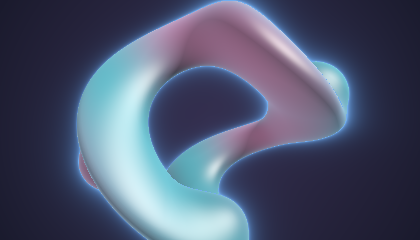

In [3]:
def sdf_smin(a: Float64, b: Float64, k: Float64) -> Float64:
    var h = clamp01(0.5 + 0.5 * (b - a) / k)
    return b * (1.0 - h) + a * h - k * h * (1.0 - h)


def sdf_sculpture(p_world: Vec3) -> Float64:
    var p = p_world.rot_y(0.52).rot_x(0.38)
    # Twist around Y axis
    var twist = 1.35 * p.y
    var ct = cos(twist)
    var st = sin(twist)
    var q = Vec3(p.x * ct - p.z * st, p.y, p.x * st + p.z * ct)

    # Major radius 1.05, minor radius 0.34 torus in XY plane
    var q_xy = sqrt(q.x * q.x + q.y * q.y) - 1.05
    var d_torus = sqrt(q_xy * q_xy + q.z * q.z) - 0.33

    # Three orbiting smooth-blended metaspheres
    var s1 = (p_world - Vec3(1.22, 0.42, 0.18)).length() - 0.38
    var s2 = (p_world - Vec3(-1.18, -0.36, 0.24)).length() - 0.36
    var s3 = (p_world - Vec3(0.05, -0.95, -0.45)).length() - 0.32
    var d = sdf_smin(d_torus, s1, 0.42)
    d = sdf_smin(d, s2, 0.42)
    d = sdf_smin(d, s3, 0.38)
    return d * 0.72  # Conservative Lipschitz factor for twist


def sdf_normal(p: Vec3) -> Vec3:
    comptime E = 0.0015
    var dx = sdf_sculpture(Vec3(p.x + E, p.y, p.z)) - sdf_sculpture(Vec3(p.x - E, p.y, p.z))
    var dy = sdf_sculpture(Vec3(p.x, p.y + E, p.z)) - sdf_sculpture(Vec3(p.x, p.y - E, p.z))
    var dz = sdf_sculpture(Vec3(p.x, p.y, p.z + E)) - sdf_sculpture(Vec3(p.x, p.y, p.z - E))
    return Vec3(dx, dy, dz).normalized()


def sdf_ao(p: Vec3, n: Vec3) -> Float64:
    var occ = 0.0
    var weight = 1.0
    for step_i in range(1, 5):
        var h = 0.07 * Float64(step_i)
        var d = sdf_sculpture(p + n * h)
        occ += (h - d) * weight
        weight *= 0.65
    return clamp01(1.0 - 2.4 * occ)


def run_sdf_sculpture() raises:
    comptime W2 = 420
    comptime H2 = 240
    var t0 = perf_counter_ns()
    var rgb = List[UInt8](length=W2 * H2 * 3, fill=0)
    var ro = Vec3(0.0, 0.12, -3.55)
    var key_l = Vec3(0.65, 0.72, -0.55).normalized()
    var fill_l = Vec3(-0.75, -0.25, -0.45).normalized()
    var inv_h = 1.0 / Float64(H2)
    var total_steps = 0

    for py in range(H2):
        for px in range(W2):
            var u = (Float64(px) + 0.5 - 0.5 * Float64(W2)) * inv_h
            var v = (0.5 * Float64(H2) - (Float64(py) + 0.5)) * inv_h
            var rd = Vec3(u, v, 1.32).normalized()

            var t = 0.0
            var hit = False
            var glow = 0.0
            for _ in range(72):
                total_steps += 1
                var p = ro + rd * t
                var d = sdf_sculpture(p)
                glow += 0.012 / (0.08 + d * d * 6.0)
                if d < 0.0018:
                    hit = True
                    break
                t += d
                if t > 8.0:
                    break

            var rad_bg = sqrt(u * u + v * v)
            var col = Vec3(0.04, 0.03, 0.09).lerp(Vec3(0.01, 0.01, 0.03), clamp01(rad_bg))
            col = col + Vec3(0.14, 0.38, 0.85) * (0.14 * glow)

            if hit:
                var pos = ro + rd * t
                var n = sdf_normal(pos)
                var ao = sdf_ao(pos, n)
                var palette_t = clamp01(0.5 + 0.45 * sin(2.4 * pos.x + 1.8 * pos.y))
                var mat = Vec3(0.15, 0.78, 0.92).lerp(Vec3(0.96, 0.36, 0.68), palette_t)

                var diff1 = max(0.0, n.dot(key_l))
                var diff2 = max(0.0, n.dot(fill_l))
                var h_vec = (key_l - rd).normalized()
                var sp = max(0.0, n.dot(h_vec))
                var sp16 = sp * sp * sp * sp
                sp16 = sp16 * sp16 * sp16 * sp16
                var fres = 1.0 - max(0.0, (-rd).dot(n))

                col = (
                    mat * (0.14 + 0.88 * diff1 + 0.30 * diff2) * ao
                    + Vec3(1.0, 0.92, 0.84) * (0.65 * sp16)
                    + Vec3(0.32, 0.72, 1.0) * (0.45 * fres * fres * fres)
                )

            var o = (py * W2 + px) * 3
            rgb[o] = tone_u8(col.x)
            rgb[o + 1] = tone_u8(col.y)
            rgb[o + 2] = tone_u8(col.z)

    var out_png = "/tmp/mojo_3d_2_sdf_torus.png"
    save_rgb_png(out_png, W2, H2, rgb)
    var ms = Int(perf_counter_ns() - t0) // 1_000_000
    print(
        "Scene 2 [SDF Twisted Torus] 420x240 |",
        total_steps // 1000,
        "K SDF evals in",
        ms,
        "ms",
    )
    print(render_ascii_strip(rgb, W2, H2, 52, 3))
    print("__TM_PLOT__ " + out_png)


run_sdf_sculpture()

## Scene 3: 3D Lorenz Strange Attractor (Volumetric Phase-Space Glow)

Integrates **80,000 3D steps** of the chaotic Lorenz differential equations ($\sigma = 10,\; \rho = 28,\; \beta = 8/3$) using RK2 midpoint integration, rotating the 3D phase portrait in perspective and accumulating HDR plasma density.

Scene 3 [3D Lorenz Attractor] 80,000 steps | peak |v| = 371 | rendered in 4 ms
  │···········░░░░················░░░··░···············│
  │········░··░░░·░░··░░░░▒▒▓▒▒░░░·····░▒░·············│
  │         ·····░·░··░░·░░▒░░░░░░░·░░··               │


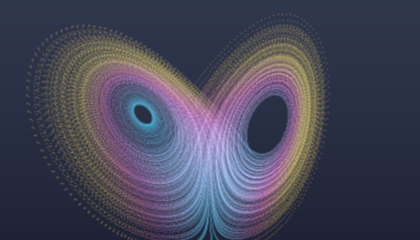

In [4]:
def lorenz_deriv(p: Vec3) -> Vec3:
    comptime SIGMA = 10.0
    comptime RHO = 28.0
    comptime BETA = 8.0 / 3.0
    return Vec3(
        SIGMA * (p.y - p.x),
        p.x * (RHO - p.z) - p.y,
        p.x * p.y - BETA * p.z,
    )


def run_lorenz_3d() raises:
    comptime W3 = 420
    comptime H3 = 240
    comptime STEPS = 80_000
    var t0 = perf_counter_ns()

    var hdr = List[Float64](length=W3 * H3 * 3, fill=0.0)
    # Dark starry gradient background
    for py in range(H3):
        var gy = Float64(py) / Float64(H3)
        for px in range(W3):
            var o = (py * W3 + px) * 3
            hdr[o] = 0.015 + 0.02 * (1.0 - gy)
            hdr[o + 1] = 0.018 + 0.03 * (1.0 - gy)
            hdr[o + 2] = 0.045 + 0.05 * (1.0 - gy)

    var p = Vec3(0.1, 0.0, 0.0)
    var dt = 0.0038
    var max_speed = 0.0

    for step in range(STEPS):
        var k1 = lorenz_deriv(p)
        var mid = p + k1 * (0.5 * dt)
        var k2 = lorenz_deriv(mid)
        p = p + k2 * dt

        if step < 400:
            continue

        var speed = k2.length()
        if speed > max_speed:
            max_speed = speed

        # Frame both butterfly wings wide in 3D perspective (X-Z lobes facing camera)
        var centered = Vec3(p.x, p.z - 26.0, p.y)
        var r3 = centered.rot_y(0.48).rot_x(0.24)
        var z_cam = r3.z + 58.0
        if z_cam <= 5.0:
            continue

        var scale = 320.0 / z_cam
        var sx = Int(0.5 * Float64(W3) + r3.x * scale)
        var sy = Int(0.52 * Float64(H3) - r3.y * scale)

        var vel_t = clamp01((speed - 18.0) / 145.0)
        var c_low = Vec3(0.08, 0.65, 1.0)
        var c_mid = Vec3(0.95, 0.22, 0.78)
        var c_hi = Vec3(1.0, 0.82, 0.20)
        var col = c_low.lerp(c_mid, clamp01(vel_t * 1.65)).lerp(
            c_hi, clamp01((vel_t - 0.48) * 1.9)
        )

        # 3x3 soft Gaussian splat
        for dy in range(-1, 2):
            var yy = sy + dy
            if yy < 0 or yy >= H3:
                continue
            for dx in range(-1, 2):
                var xx = sx + dx
                if xx < 0 or xx >= W3:
                    continue
                var wgt = 0.052 if (dx == 0 and dy == 0) else (0.020 if (dx * dy == 0) else 0.009)
                var idx = (yy * W3 + xx) * 3
                hdr[idx] += col.x * wgt
                hdr[idx + 1] += col.y * wgt
                hdr[idx + 2] += col.z * wgt

    var rgb = List[UInt8](length=W3 * H3 * 3, fill=0)
    for k in range(W3 * H3 * 3):
        rgb[k] = tone_u8(hdr[k])

    var out_png = "/tmp/mojo_3d_3_lorenz.png"
    save_rgb_png(out_png, W3, H3, rgb)
    var ms = Int(perf_counter_ns() - t0) // 1_000_000
    print(
        "Scene 3 [3D Lorenz Attractor] 80,000 steps | peak |v| =",
        Int(max_speed),
        "| rendered in",
        ms,
        "ms",
    )
    print(render_ascii_strip(rgb, W3, H3, 52, 3))
    print("__TM_PLOT__ " + out_png)


run_lorenz_3d()

## Scene 4: Z-Buffered 3D Parametric Wave Interference Mesh

Evaluates a two-source 3D damped wave surface $z(x, y) = \cos(r_1)e^{-0.11 r_1} + 0.75\cos(r_2)e^{-0.11 r_2}$ over a fine parametric grid, projecting into 3D perspective with a per-pixel **depth buffer (`zbuf`)** and glowing wireframe isolines.

Scene 4 [Z-Buffered 3D Wave Mesh] 176400 surface samples rendered in 25 ms
  │                      ░░░░░░░░░░░░                  │
  │         ▓▓░·░▒▓▓░░░░░░░···░░░░░░░░░▒░░░░           │
  │                                                    │


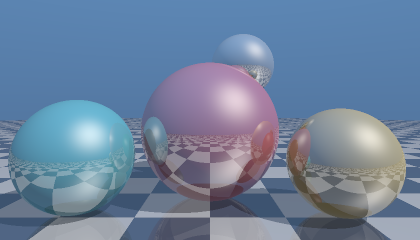

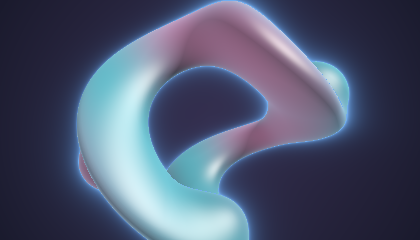

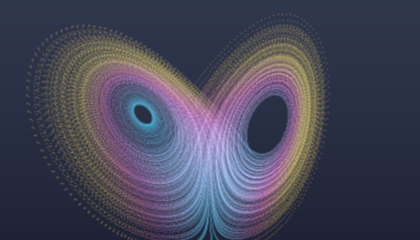

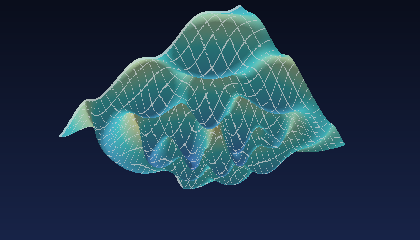

In [5]:
def wave_height(x: Float64, y: Float64) -> Float64:
    var r1 = sqrt((x + 2.1) * (x + 2.1) + (y + 1.2) * (y + 1.2))
    var r2 = sqrt((x - 2.2) * (x - 2.2) + (y - 1.4) * (y - 1.4))
    return 1.35 * cos(2.2 * r1) * exp(-0.14 * r1) + 1.05 * cos(2.4 * r2) * exp(-0.14 * r2)


def run_wave_surface_3d() raises:
    comptime W4 = 420
    comptime H4 = 240
    comptime GRID = 420
    var t0 = perf_counter_ns()

    var rgb = List[UInt8](length=W4 * H4 * 3, fill=0)
    var zbuf = List[Float64](length=W4 * H4, fill=1e9)

    for py in range(H4):
        var gy = Float64(py) / Float64(H4)
        for px in range(W4):
            var o = (py * W4 + px) * 3
            rgb[o] = UInt8(Int(10.0 + 14.0 * gy))
            rgb[o + 1] = UInt8(Int(14.0 + 22.0 * gy))
            rgb[o + 2] = UInt8(Int(28.0 + 44.0 * gy))

    var light_dir = Vec3(-0.45, 0.78, -0.42).normalized()

    for gi in range(GRID):
        var u = -6.5 + 13.0 * (Float64(gi) / Float64(GRID - 1))
        for gj in range(GRID):
            var v = -6.5 + 13.0 * (Float64(gj) / Float64(GRID - 1))
            var z = wave_height(u, v)

            # Central-difference surface normal on heightfield
            var dz_du = (wave_height(u + 0.04, v) - wave_height(u - 0.04, v)) / 0.08
            var dz_dv = (wave_height(u, v + 0.04) - wave_height(u, v - 0.04)) / 0.08
            var n = Vec3(-dz_du, 1.0, -dz_dv).normalized()

            var p3 = Vec3(u, z * 1.12, v).rot_y(0.68).rot_x(0.56)
            var z_cam = p3.z + 16.4
            if z_cam <= 1.0:
                continue

            var f = 250.0 / z_cam
            var sx = Int(0.5 * Float64(W4) + p3.x * f)
            var sy = Int(0.56 * Float64(H4) - p3.y * f)

            var is_wire = (gi % 15 == 0) or (gj % 15 == 0)
            var elev_t = clamp01((z + 1.8) / 3.6)
            var deep_c = Vec3(0.08, 0.26, 0.72)
            var mid_c = Vec3(0.08, 0.84, 0.76)
            var peak_c = Vec3(1.0, 0.78, 0.24)
            var surf = deep_c.lerp(mid_c, clamp01(elev_t * 1.7)).lerp(
                peak_c, clamp01((elev_t - 0.48) * 1.9)
            )

            var diff = max(0.0, n.rot_y(0.68).rot_x(0.56).dot(light_dir))
            var col = surf * (0.28 + 0.85 * diff)
            if is_wire:
                col = col.lerp(Vec3(0.88, 0.98, 1.0), 0.52)

            for dy in range(2):
                var yy = sy + dy
                if yy < 0 or yy >= H4:
                    continue
                for dx in range(2):
                    var xx = sx + dx
                    if xx < 0 or xx >= W4:
                        continue
                    var pidx = yy * W4 + xx
                    if z_cam < zbuf[pidx]:
                        zbuf[pidx] = z_cam
                        var o = pidx * 3
                        rgb[o] = tone_u8(col.x)
                        rgb[o + 1] = tone_u8(col.y)
                        rgb[o + 2] = tone_u8(col.z)

    var out_png = "/tmp/mojo_3d_4_wave_mesh.png"
    save_rgb_png(out_png, W4, H4, rgb)
    var ms = Int(perf_counter_ns() - t0) // 1_000_000
    print(
        "Scene 4 [Z-Buffered 3D Wave Mesh]",
        GRID * GRID,
        "surface samples rendered in",
        ms,
        "ms",
    )
    print(render_ascii_strip(rgb, W4, H4, 52, 3))
    # Emit all 4 scene plots if generated so `Text > Open cell plot preview` shows the full 3D deck!
    for p_cand in [
        "/tmp/mojo_3d_1_raytracer.png",
        "/tmp/mojo_3d_2_sdf_torus.png",
        "/tmp/mojo_3d_3_lorenz.png",
    ]:
        if Path(p_cand).exists():
            print("__TM_PLOT__ " + p_cand)
    print("__TM_PLOT__ " + out_png)


run_wave_surface_3d()